# Experiment 1: Exploring Quantum State Evolution Using the Bloch Sphere in Qiskit

**Course:** Quantum Computing and Algorithms  
**Name:** Ritesh Roshan Sahoo  
**Roll Number:** DL.AI.U4AID24036  
**Email:** riteshroshansahoo01@gmail.com

## Aim

To prepare, visualise and optimise single-qubit states in Qiskit using the Bloch sphere, to reverse engineer circuits from observed outputs, to characterise the standard gates experimentally and to investigate where the Bloch sphere stops being a complete description.

## Setup

In [1]:
%pip install --quiet qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator, Pauli
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit.visualization.bloch import Bloch
from qiskit_aer import AerSimulator

simulator = AerSimulator()

# Display circuit using Matplotlib and pylatexenc
def show_circuit(qc, title):
    print("\n" + title)
    display(qc.draw(output="mpl"))

# Display statevector
def show_state(qc):
    print("Statevector:", np.round(
        Statevector.from_instruction(qc).data, 3
    ))

# Display measurement histogram
def show_histogram(qc, title):
    measured = qc.copy()
    measured.measure_all()
    result = simulator.run(
        transpile(measured, simulator), shots=1024
    ).result()
    counts = result.get_counts()
    print("Measurement counts:", counts)
    display(plot_histogram(counts, title=title))

# Bloch vector of a state as (x, y, z)
def bloch_xyz(state):
    return [state.expectation_value(Pauli(p)).real for p in "XYZ"]

# One Bloch sphere after every gate of a single-qubit circuit
def bloch_evolution(qc):
    steps = len(qc.data)
    fig = plt.figure(figsize=(3.2 * (steps + 1), 3.2))
    partial = QuantumCircuit(1)
    for k in range(steps + 1):
        if k > 0:
            partial.append(qc.data[k - 1])
        state = Statevector.from_instruction(partial)
        ax = fig.add_subplot(1, steps + 1, k + 1, projection="3d")
        sphere = Bloch(fig=fig, axes=ax)
        sphere.add_vectors([bloch_xyz(state)])
        if k == 0:
            name = "start"
        else:
            name = "after " + qc.data[k - 1].operation.name.upper()
        sphere.render(title=name)
    plt.close(fig)
    return fig

## Task 1: Quantum Circuit Optimization Challenge

### Problem Statement

The target state is $|1\rangle$. Design at least three different circuits that prepare it from $|0\rangle$ using only the gates $X, Y, Z, H, S, T$ (no rotation gates), verify each with the statevector, plot the Bloch sphere evolution, optimise each circuit with the Qiskit transpiler and compare depth, gate count, number of phase gates and the transpiled metrics.

### Program


Task 1 - Circuit 1


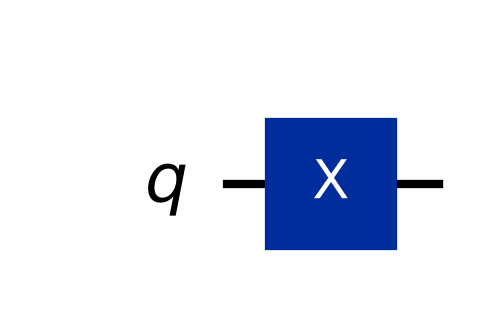

Statevector: [0.+0.j 1.+0.j]


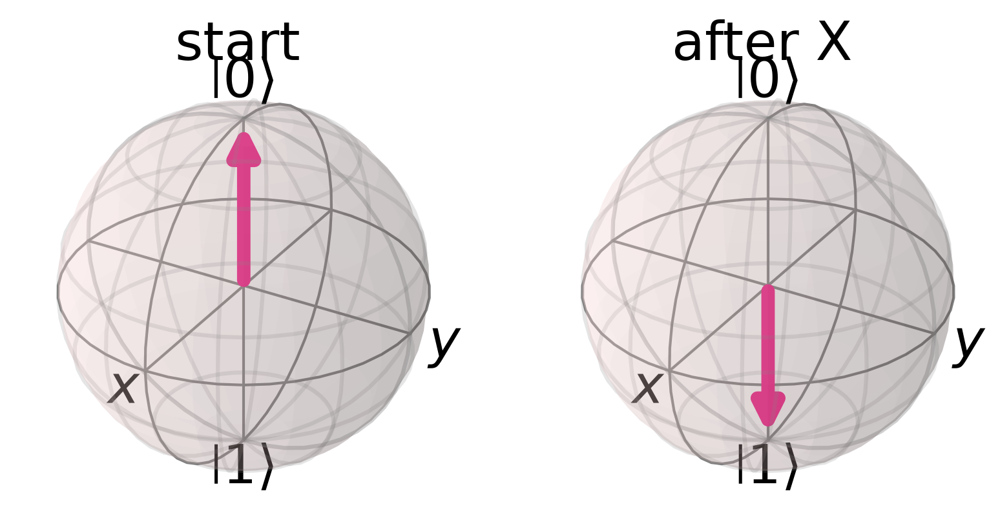

Depth: 1
Gate counts: {'x': 1}
Phase gates: 0
Optimized depth: 1
Optimized gate counts: {'u': 1}

Task 1 - Circuit 2


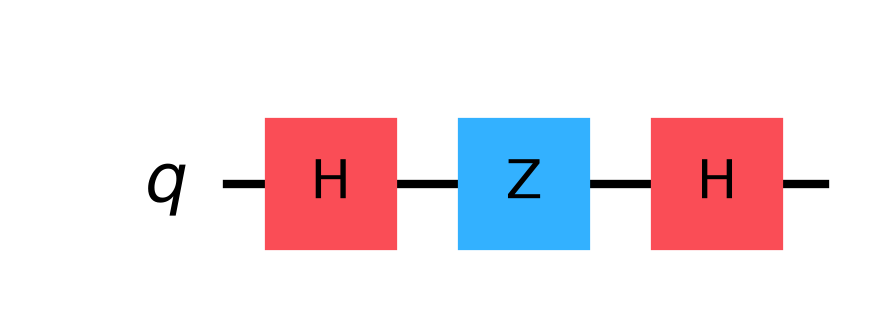

Statevector: [0.+0.j 1.+0.j]


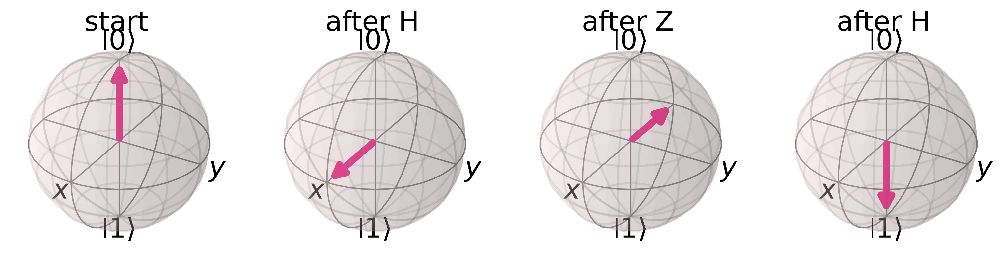

Depth: 3
Gate counts: {'h': 2, 'z': 1}
Phase gates: 1
Optimized depth: 1
Optimized gate counts: {'u': 1}

Task 1 - Circuit 3


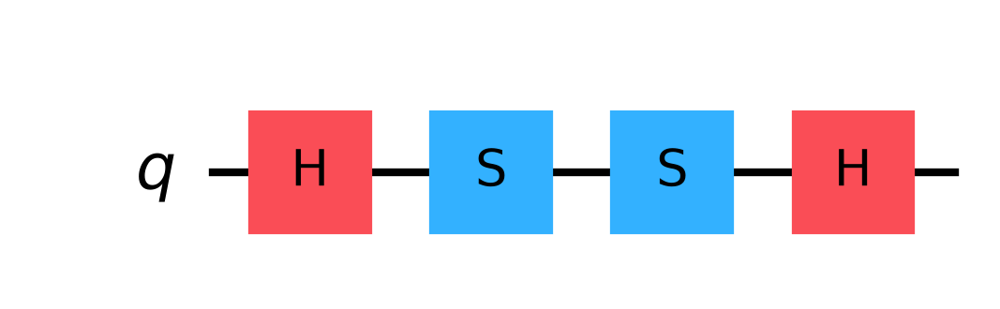

Statevector: [0.+0.j 1.+0.j]


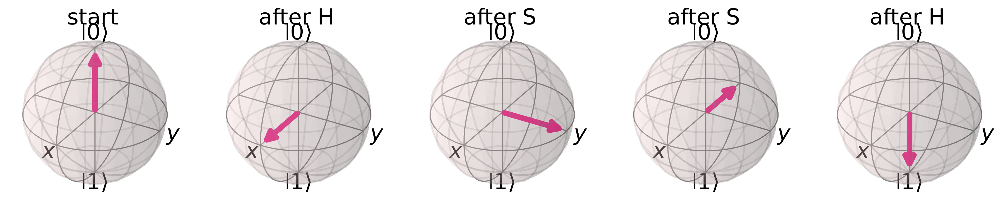

Depth: 4
Gate counts: {'h': 2, 's': 2}
Phase gates: 2
Optimized depth: 1
Optimized gate counts: {'u': 1}


In [3]:
# Three circuits that prepare |1> from |0>
q1 = QuantumCircuit(1)
q1.x(0)

q2 = QuantumCircuit(1)
q2.h(0)
q2.z(0)
q2.h(0)

q3 = QuantumCircuit(1)
q3.h(0)
q3.s(0)
q3.s(0)
q3.h(0)

phase_gates = {"z", "s", "t", "sdg", "tdg"}

for i, qc in enumerate([q1, q2, q3], 1):
    show_circuit(qc, f"Task 1 - Circuit {i}")
    show_state(qc)
    display(bloch_evolution(qc))

    optimized = transpile(
        qc, basis_gates=["u", "cx"], optimization_level=3
    )
    ops = qc.count_ops()
    print("Depth:", qc.depth())
    print("Gate counts:", dict(ops))
    print("Phase gates:",
          sum(ops[g] for g in ops if g in phase_gates))
    print("Optimized depth:", optimized.depth())
    print("Optimized gate counts:", dict(optimized.count_ops()))

### Observation

| Circuit | Gates | Depth | Phase gates | After transpile (u, cx) |
| --- | --- | --- | --- | --- |
| 1: X | 1 | 1 | 0 | 1 gate, depth 1 |
| 2: H Z H | 3 | 3 | 1 | 1 gate, depth 1 |
| 3: H S S H | 4 | 4 | 2 | 1 gate, depth 1 |
*Comparison of the three preparations of the target state*

All three circuits give the statevector $[0, 1]$ and the same Bloch vector $(0, 0, -1)$, so they prepare the same state. **Circuit 1 is optimal**: one gate, depth 1 and no phase gates. The transpiler recognises that $HZH = X$ and $S S = Z$ and **collapses circuits 2 and 3 to a single `u` gate**, which confirms that the extra gates were pure overhead.

## Task 2: Reverse Engineer the Unknown Circuit

### Problem Statement

A hidden single-qubit circuit maps $|0\rangle$ to $|+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$ with a 512/512 histogram and Bloch vector $(1, 0, 0)$. Reconstruct at least two different circuits that produce this output, verify the statevector, histogram and Bloch sphere, compute the unitary of each and decide whether the circuits are the same operation. Then build two circuits with **different** unitaries that still give $|+\rangle$ for the input $|0\rangle$, and transpile every circuit to see what Qiskit can simplify.

### Program


Task 2 - Circuit A


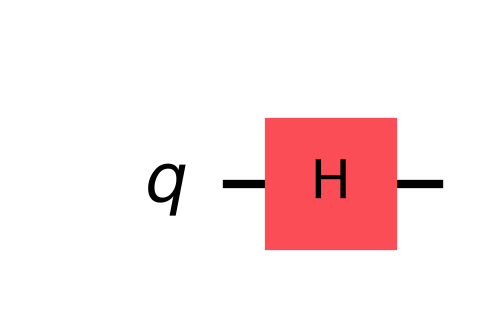

Statevector: [0.707+0.j 0.707+0.j]
Unitary matrix:
 [[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]


Measurement counts:

 {'0': 513, '1': 511}


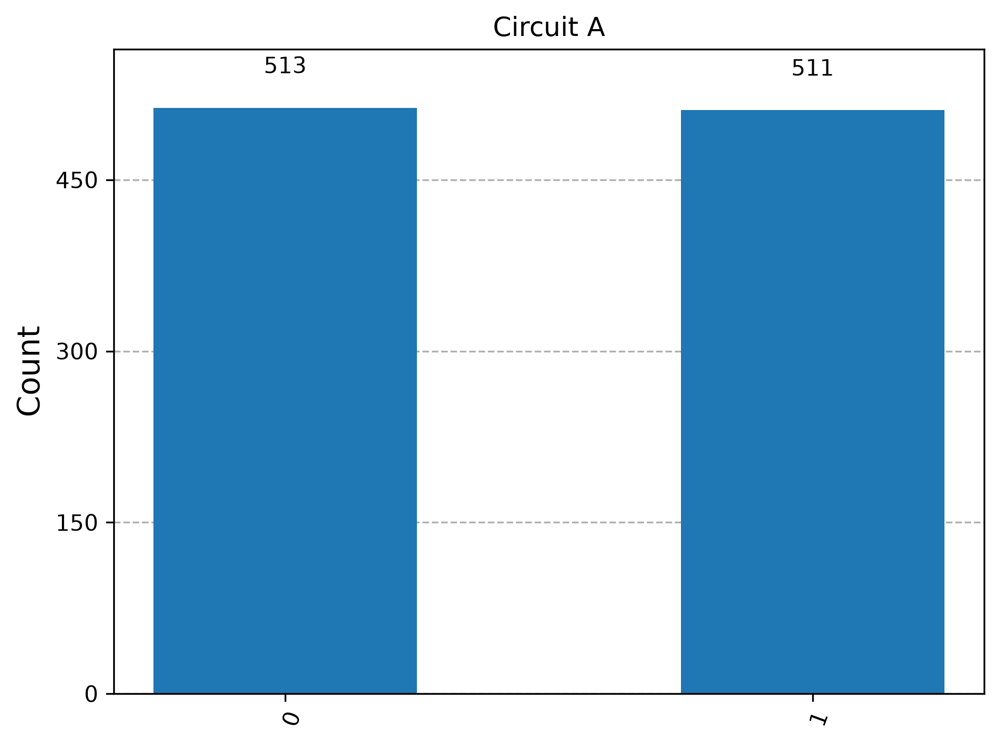

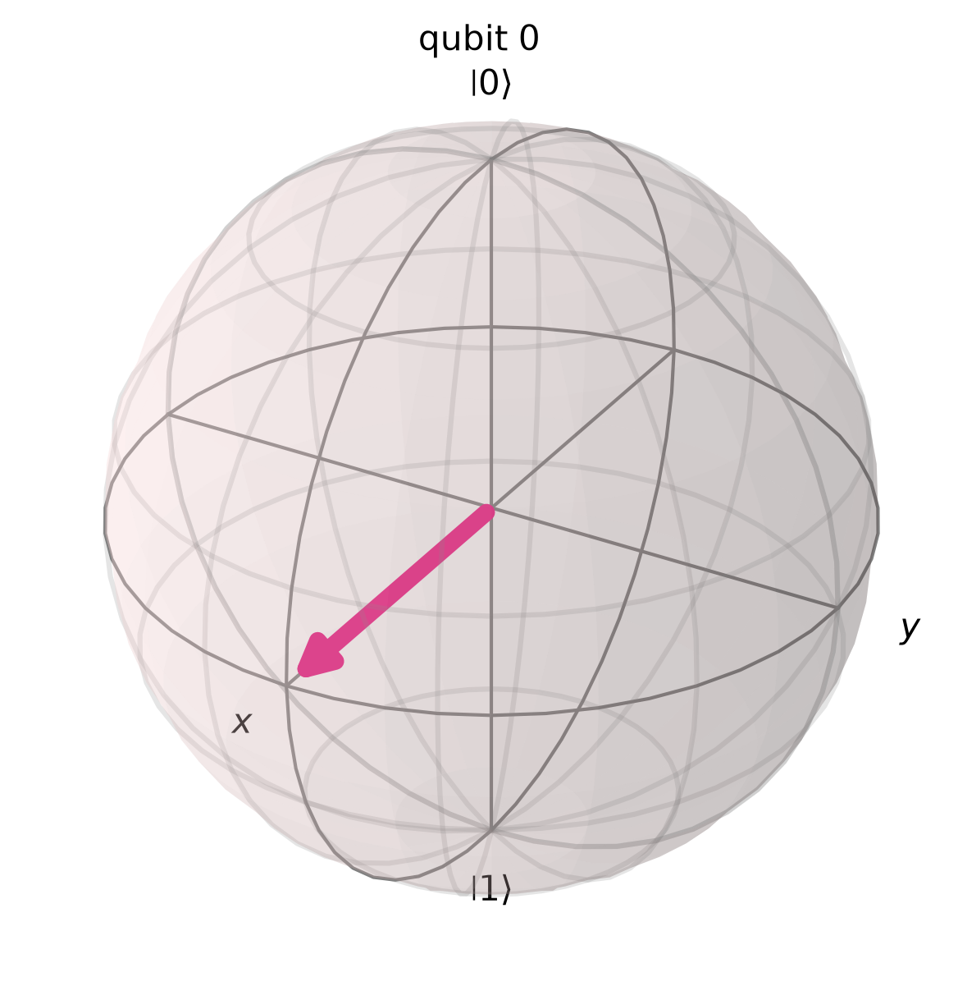


Task 2 - Circuit B


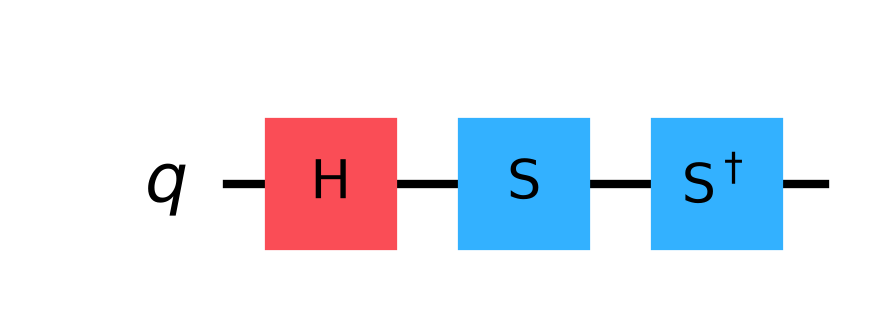

Statevector: [0.707+0.j 0.707+0.j]
Unitary matrix:
 [[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]


Measurement counts: {'1': 547, '0': 477}


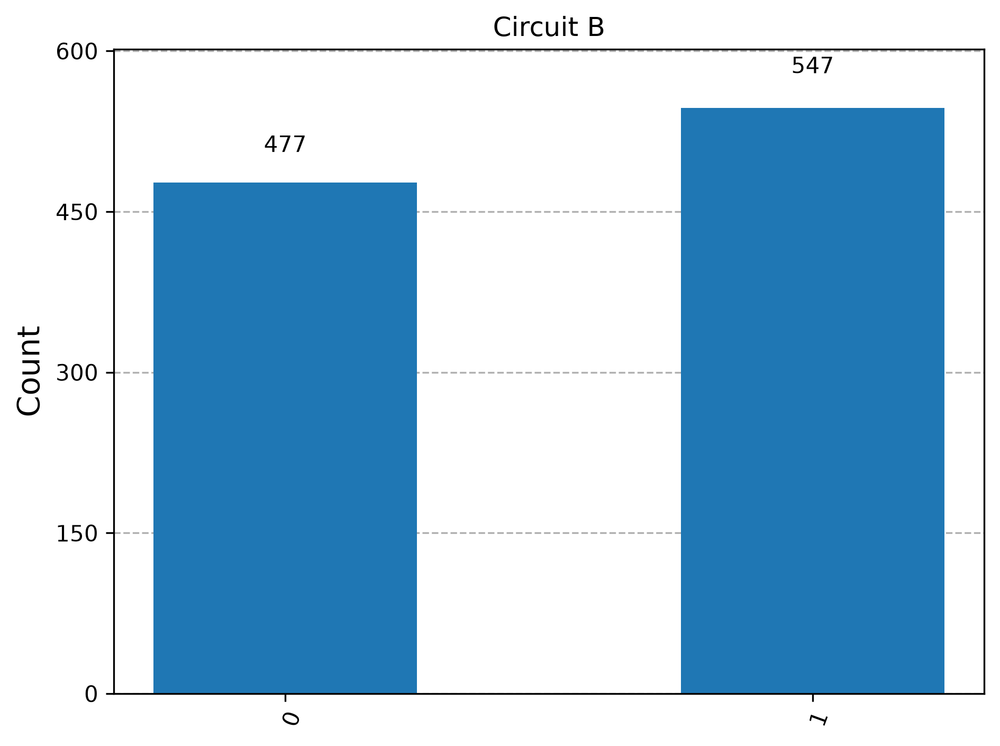

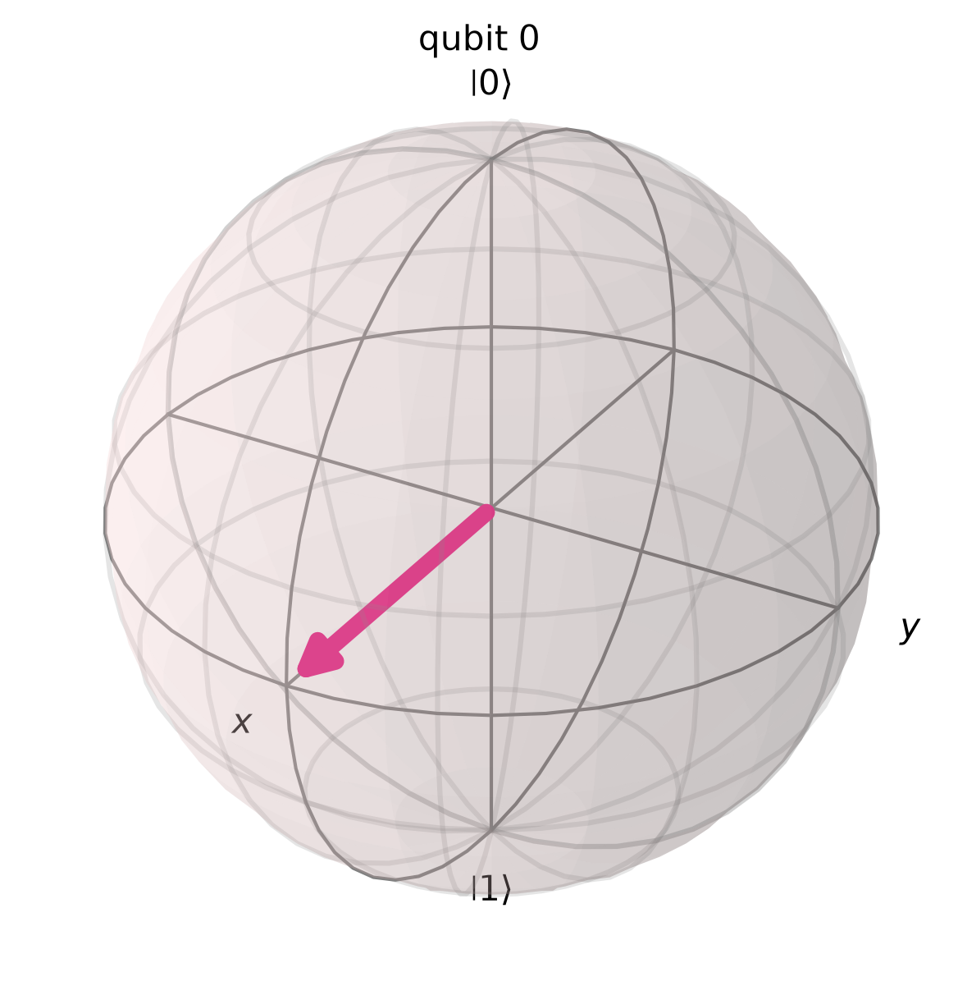

Same unitary: True


In [4]:
# Circuit A: H |0> = |+>
c1 = QuantumCircuit(1)
c1.h(0)

# Circuit B: H followed by S and S-dagger
c2 = QuantumCircuit(1)
c2.h(0)
c2.s(0)
c2.sdg(0)

for name, qc in [("Circuit A", c1), ("Circuit B", c2)]:
    show_circuit(qc, "Task 2 - " + name)
    show_state(qc)
    print("Unitary matrix:\n", np.round(Operator(qc).data, 3))
    show_histogram(qc, name)
    display(plot_bloch_multivector(
        Statevector.from_instruction(qc)
    ))

print("Same unitary:", Operator(c1).equiv(Operator(c2)))

In [5]:
# Extension: same output for |0>, different unitary
e1 = QuantumCircuit(1)
e1.h(0)

e2 = QuantumCircuit(1)
e2.s(0)
e2.h(0)

print("U_C1 =\n", np.round(Operator(e1).data, 3))
print("U_C2 =\n", np.round(Operator(e2).data, 3))
print("Same unitary:", Operator(e1).equiv(Operator(e2)))

for label in ["0", "1", "+"]:
    out1 = Statevector.from_label(label).evolve(e1)
    out2 = Statevector.from_label(label).evolve(e2)
    print(f"\nInput |{label}>")
    print("  C1 output:", np.round(out1.data, 3))
    print("  C2 output:", np.round(out2.data, 3))
    print("  Same state:", out1.equiv(out2))

U_C1 =
 [[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]
U_C2 =
 [[0.707+0.j    0.   +0.707j]
 [0.707+0.j    0.   -0.707j]]
Same unitary: False

Input |0>
  C1 output: [0.707+0.j 0.707+0.j]
  C2 output: [0.707+0.j 0.707+0.j]
  Same state: True

Input |1>
  C1 output: [ 0.707+0.j -0.707+0.j]
  C2 output: [0.+0.707j 0.-0.707j]
  Same state: True

Input |+>
  C1 output: [1.+0.j 0.+0.j]
  C2 output: [0.5+0.5j 0.5-0.5j]
  Same state: False


In [6]:
# Circuit optimisation with the transpiler
circuits = [("Circuit A", c1), ("Circuit B", c2), ("C2 = S H", e2)]
for name, qc in circuits:
    optimized = transpile(
        qc, basis_gates=["u", "cx"], optimization_level=3
    )
    print(name)
    print("  original : depth", qc.depth(),
          "gates", dict(qc.count_ops()))
    print("  optimized: depth", optimized.depth(),
          "gates", dict(optimized.count_ops()))

Circuit A
  original : depth 1 gates {'h': 1}
  optimized: depth 1 gates {'u': 1}
Circuit B
  original : depth 3 gates {'h': 1, 's': 1, 'sdg': 1}
  optimized: depth 1 gates {'u': 1}
C2 = S H
  original : depth 2 gates {'s': 1, 'h': 1}
  optimized: depth 1 gates {'u': 1}


### Observation

**Circuits A and B implement exactly the same unitary**, the Hadamard matrix, because $S S^\dagger = I$. Both give the statevector $[0.707, 0.707]$, a histogram close to 512/512 and the Bloch vector $(1, 0, 0)$.

In the extension, $C_1 = H$ and $C_2 = S$ followed by $H$ have **different unitaries** but both map $|0\rangle$ to $|+\rangle$, because $S|0\rangle = |0\rangle$. For the input $|1\rangle$ the outputs differ only by a global phase $i$, so they are still the same physical state, but for the input $|+\rangle$ the outputs are different states. **Equal output for one input does not mean equal operation**; a unitary is only fixed by its action on a full basis.

The transpiler reduces Circuit B from **3 gates to 1**, since the cancelling pair is removed, while Circuit A is already minimal.

## Task 3: Quantum Gate Discovery

### Problem Statement

Treat $X, Y, Z, H, S, T$ as black boxes. Using only experiments, find the rotation axis and angle of each gate, its effect on measurement probabilities, the phase it introduces, whether it is self-inverse and whether it equals a sequence of other gates.

### Experimental Procedure

- **Axis and angle**: apply the gate to $|0\rangle$, $|1\rangle$ and $|+\rangle$ and plot the three output Bloch vectors on one sphere. The vector that does not move lies on the rotation axis; the angle is read from how far the other vectors turn.
- **Probabilities and phase**: print the output statevector and measurement probabilities for each input.
- **Self-inverse**: apply the gate twice and compare with the input state.
- **Equivalences**: compare the unitary of candidate gate sequences with `Operator.equiv`.

### Program


===== X GATE =====
   ┌───┐
q: ┤ X ├
   └───┘
Unitary matrix:
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
|0> -> [0.+0.j 1.+0.j] Probabilities: [0. 1.]
|1> -> [1.+0.j 0.+0.j] Probabilities: [1. 0.]
|+> -> [0.707+0.j 0.707+0.j] Probabilities: [0.5 0.5]


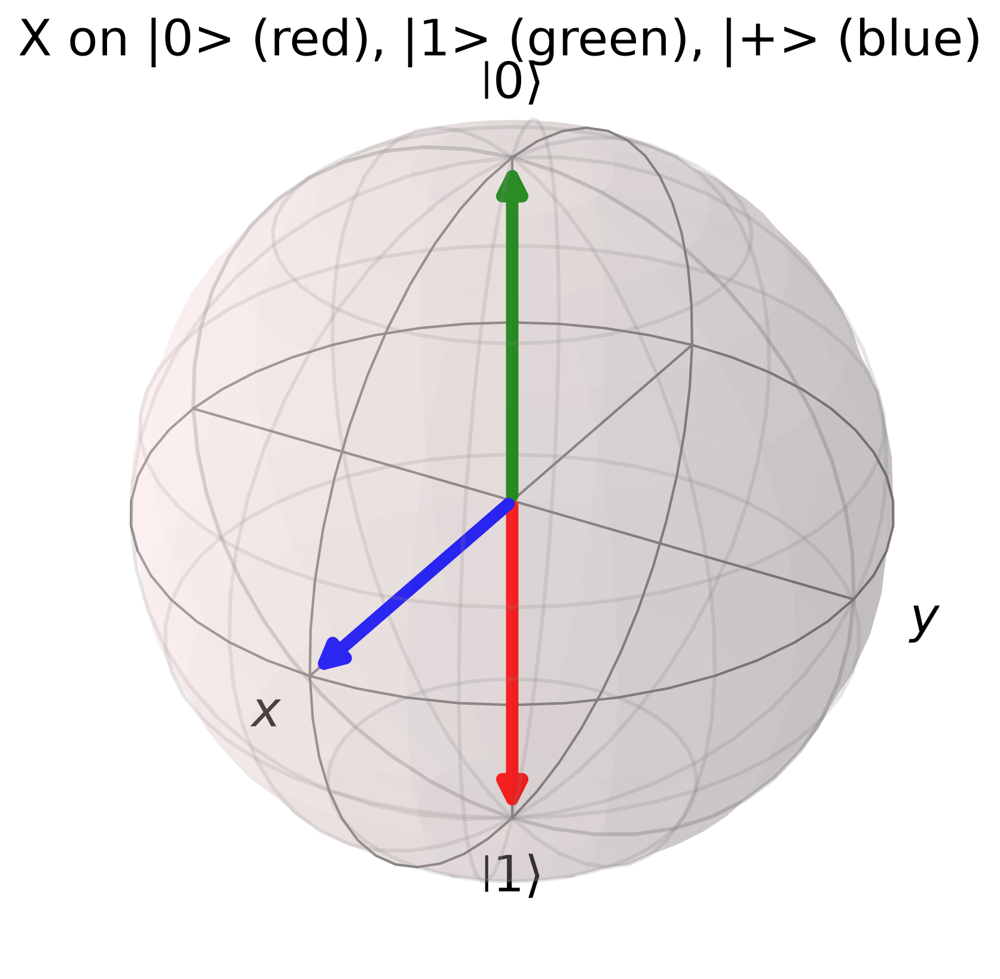


===== Y GATE =====
   ┌───┐
q: ┤ Y ├
   └───┘
Unitary matrix:
 [[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]
|0> -> [0.+0.j 0.+1.j] Probabilities: [0. 1.]
|1> -> [0.-1.j 0.+0.j] Probabilities: [1. 0.]
|+> -> [0.-0.707j 0.+0.707j] Probabilities: [0.5 0.5]


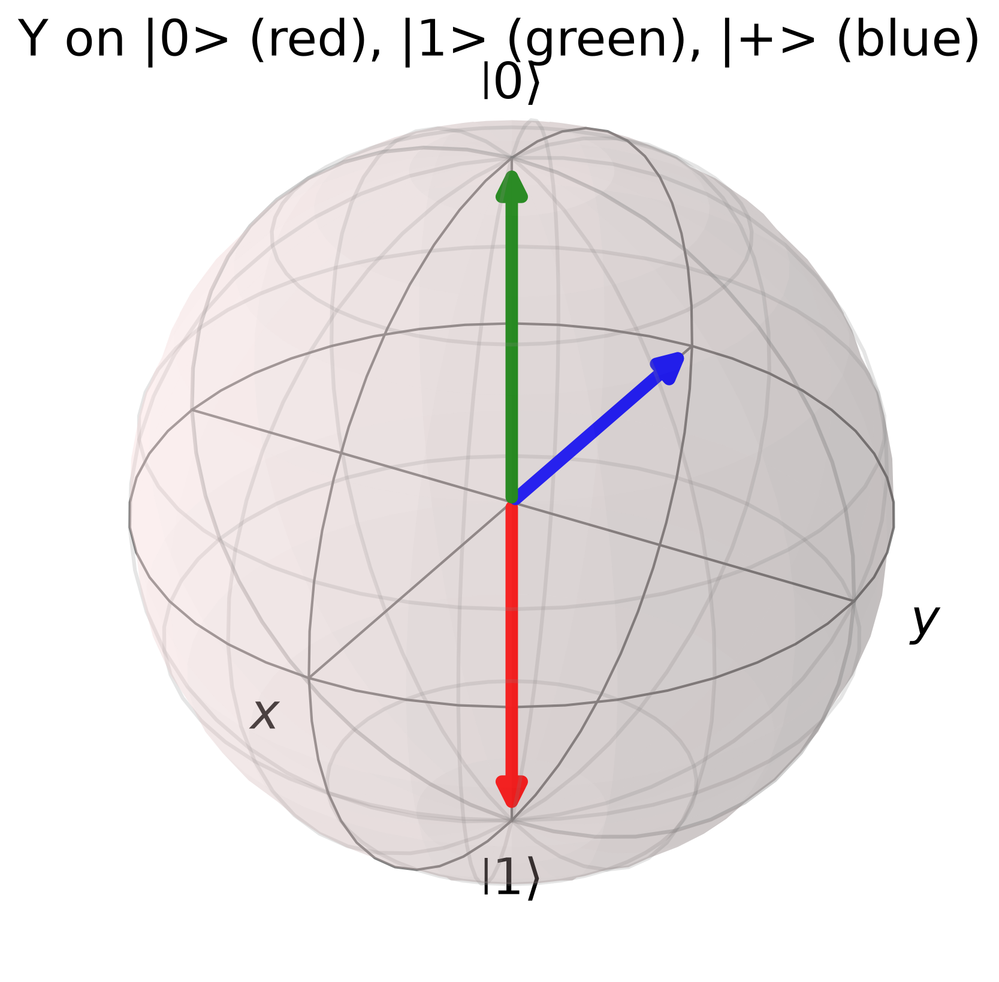


===== Z GATE =====
   ┌───┐
q: ┤ Z ├
   └───┘
Unitary matrix:
 [[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]
|0> -> [1.+0.j 0.+0.j] Probabilities: [1. 0.]
|1> -> [ 0.+0.j -1.+0.j] Probabilities: [0. 1.]
|+> -> [ 0.707+0.j -0.707+0.j] Probabilities: [0.5 0.5]


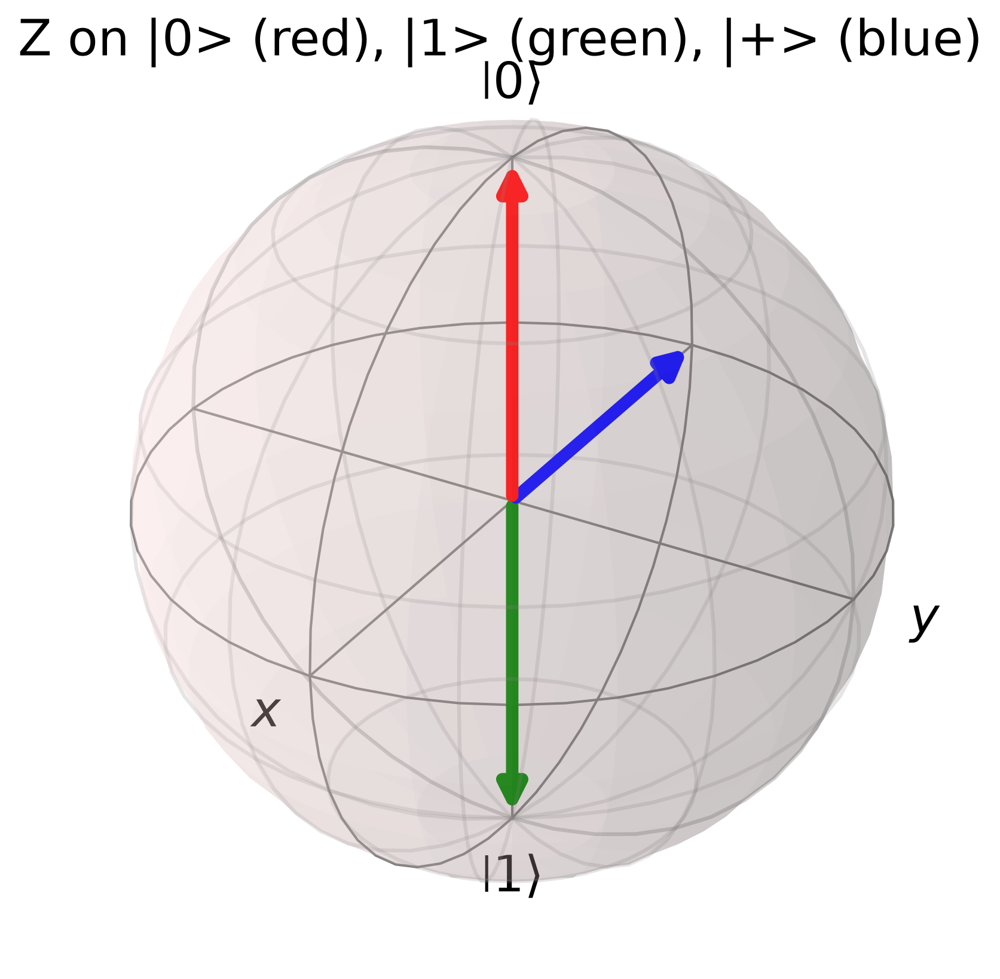


===== H GATE =====
   ┌───┐
q: ┤ H ├
   └───┘
Unitary matrix:
 [[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]
|0> -> [0.707+0.j 0.707+0.j] Probabilities: [0.5 0.5]
|1> -> [ 0.707+0.j -0.707+0.j] Probabilities: [0.5 0.5]
|+> -> [1.+0.j 0.+0.j] Probabilities: [1. 0.]


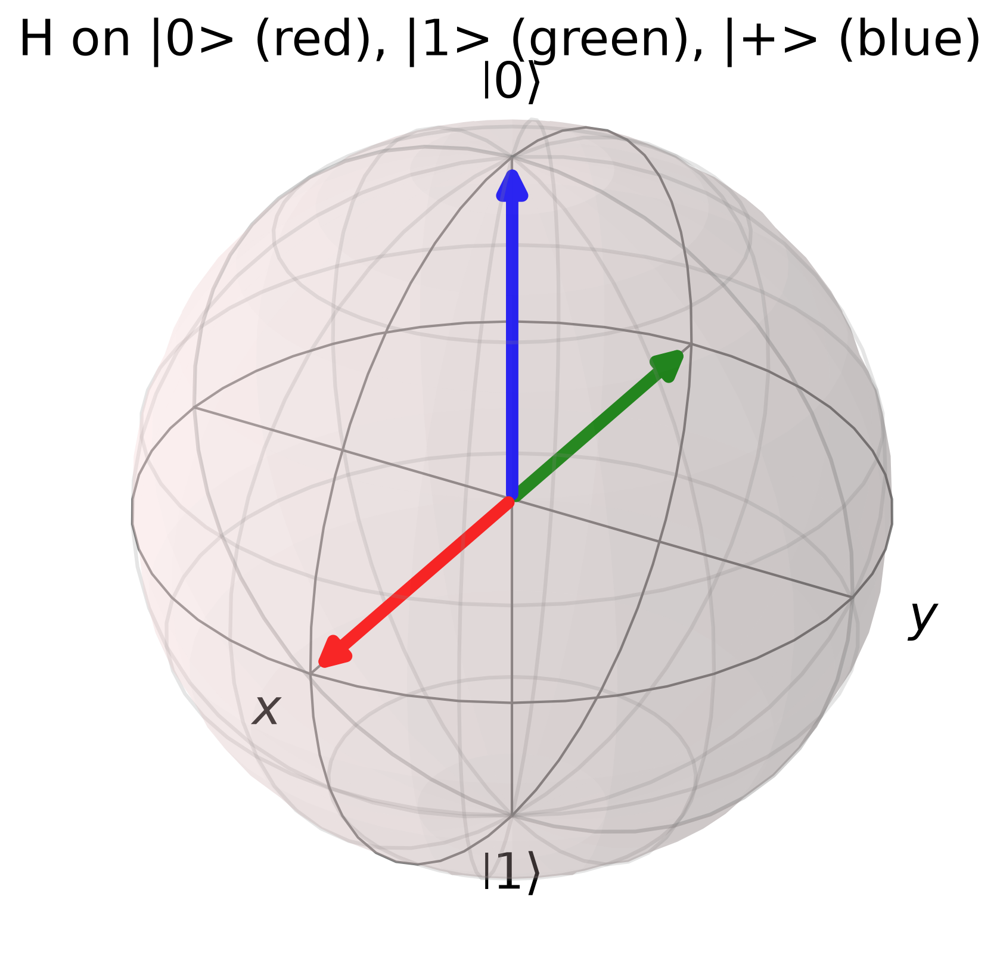


===== S GATE =====
   ┌───┐
q: ┤ S ├
   └───┘
Unitary matrix:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]
|0> -> [1.+0.j 0.+0.j] Probabilities: [1. 0.]
|1> -> [0.+0.j 0.+1.j] Probabilities: [0. 1.]
|+> -> [0.707+0.j    0.   +0.707j] Probabilities: [0.5 0.5]


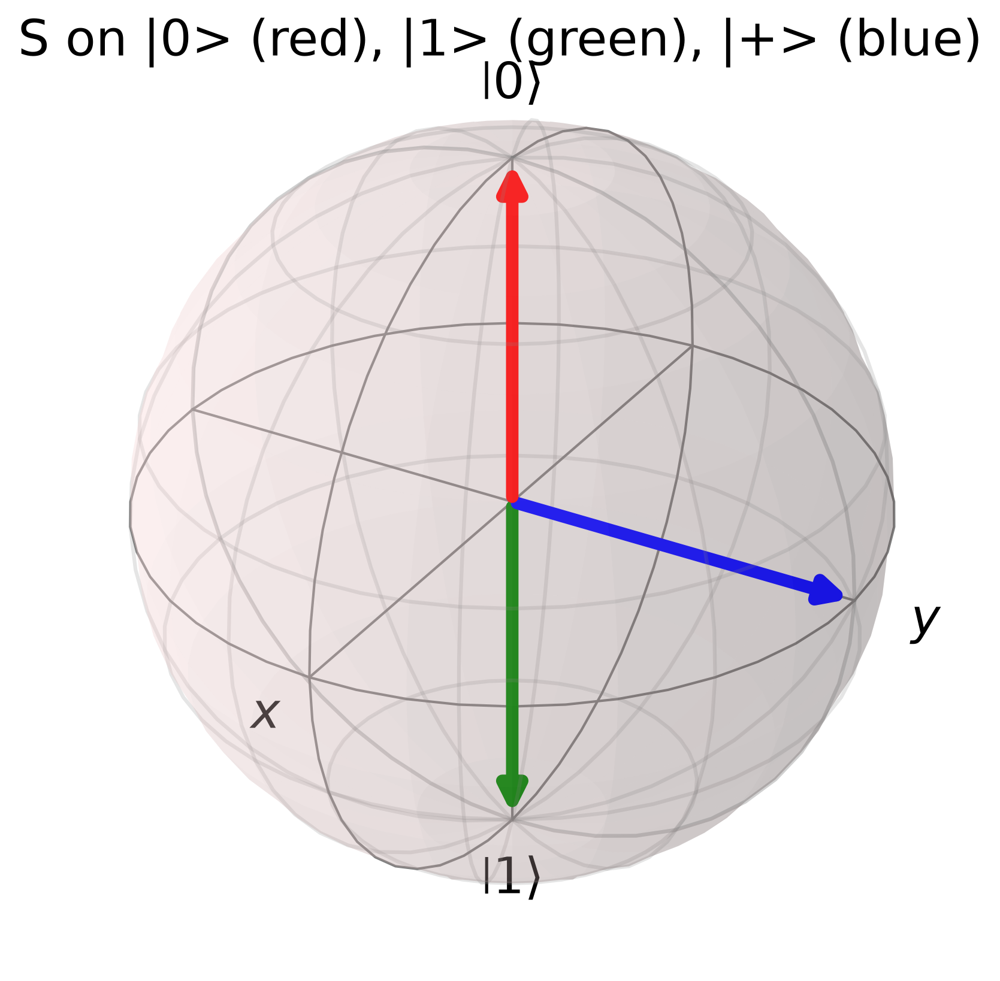


===== T GATE =====
   ┌───┐
q: ┤ T ├
   └───┘
Unitary matrix:
 [[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]]
|0> -> [1.+0.j 0.+0.j] Probabilities: [1. 0.]
|1> -> [0.   +0.j    0.707+0.707j] Probabilities: [0. 1.]
|+> -> [0.707+0.j  0.5  +0.5j] Probabilities: [0.5 0.5]


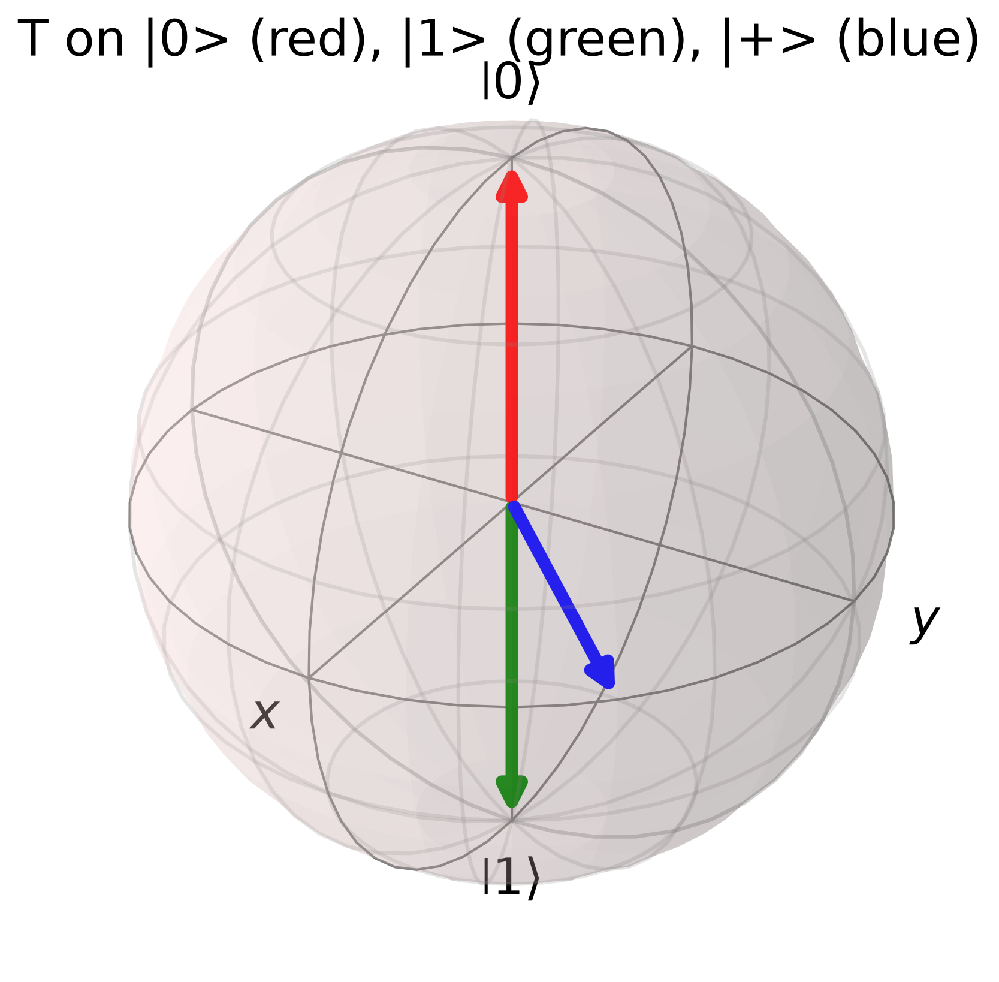

In [7]:
gates = ["X", "Y", "Z", "H", "S", "T"]
inputs = ["0", "1", "+"]

def apply_gate(gate, input_state):
    qc = QuantumCircuit(1)
    if input_state == "1":
        qc.x(0)
    elif input_state == "+":
        qc.h(0)
    getattr(qc, gate.lower())(0)
    return Statevector.from_instruction(qc)

for gate in gates:
    qc = QuantumCircuit(1)
    getattr(qc, gate.lower())(0)
    print(f"\n===== {gate} GATE =====")
    print(qc.draw())
    print("Unitary matrix:\n", np.round(Operator(qc).data, 3))

    sphere = Bloch()
    sphere.vector_color = ["r", "g", "b"]
    for state in inputs:
        output = apply_gate(gate, state)
        print(f"|{state}> -> {np.round(output.data, 3)}",
              "Probabilities:", np.round(output.probabilities(), 3))
        sphere.add_vectors([bloch_xyz(output)])
    sphere.render(
        title=f"{gate} on |0> (red), |1> (green), |+> (blue)"
    )
    display(sphere.fig)
    plt.close(sphere.fig)

In [8]:
# Self-inverse test: apply each gate twice
def apply_twice(gate, input_state):
    qc = QuantumCircuit(1)
    for _ in range(2):
        getattr(qc, gate.lower())(0)
    return Statevector.from_label(input_state).evolve(qc)

for gate in gates:
    same = True
    for state in inputs:
        original = Statevector.from_label(state)
        output = apply_twice(gate, state)
        if not np.allclose(original.data, output.data, atol=1e-8):
            same = False
    print(f"{gate} Self-Inverse: {same}")

X Self-Inverse: True
Y Self-Inverse: True
Z Self-Inverse: True
H Self-Inverse: True
S Self-Inverse: False
T Self-Inverse: False


In [9]:
# Equivalent circuits, compared through their unitaries
def unitary(*names):
    qc = QuantumCircuit(1)
    for name in names:
        getattr(qc, name)(0)
    return Operator(qc)

checks = {
    "S S = Z": (unitary("s", "s"), unitary("z")),
    "T T = S": (unitary("t", "t"), unitary("s")),
    "H Z H = X": (unitary("h", "z", "h"), unitary("x")),
    "H X H = Z": (unitary("h", "x", "h"), unitary("z")),
    "X Z = Y (up to phase)": (unitary("x", "z"), unitary("y")),
}
for name, (a, b) in checks.items():
    print(f"{name}: {a.equiv(b)}")

S S = Z: True
T T = S: True
H Z H = X: True
H X H = Z: True
X Z = Y (up to phase): True


### Observation

| Gate | Rotation axis | Angle | Self-inverse | Phase change | Equivalent circuit |
| --- | --- | --- | --- | --- | --- |
| X | x | $\pi$ | Yes | none on $|+\rangle$ | H Z H |
| Y | y | $\pi$ | Yes | $\pm i$ on $|0\rangle, |1\rangle$ | X Z up to phase |
| Z | z | $\pi$ | Yes | $-1$ on $|1\rangle$ | S S, H X H |
| H | (x+z)/$\sqrt{2}$ | $\pi$ | Yes | none | self-inverse |
| S | z | $\pi/2$ | No | $i$ on $|1\rangle$ | T T |
| T | z | $\pi/4$ | No | $e^{i\pi/4}$ on $|1\rangle$ | square root of S |
*Experimental investigation of single-qubit gates*

The Bloch plots show which input vector stays fixed: $|+\rangle$ for X, $|0\rangle$ and $|1\rangle$ for Z, S and T. **Z, S and T all rotate about the z axis** and never change the measurement probabilities of $|0\rangle$ or $|1\rangle$; they differ only in the phase on $|1\rangle$. **X, Y, Z and H are self-inverse** (rotation by $\pi$) while **S and T are not**, and the equivalences $S S = Z$, $T T = S$ and $HZH = X$ were all confirmed by `Operator.equiv`.

## Task 4: Bloch Sphere Navigation Challenge

### Problem Statement

Design one circuit that moves the qubit through the five states $|0\rangle \to |1\rangle \to |-\rangle \to |-i\rangle \to |+i\rangle$ in order. Record the Bloch sphere and statevector after every gate, explain each transition, minimise the number of gates, depth and phase gates, compare with another valid solution and decide experimentally whether more than one optimal navigation circuit exists.

### Program

After gate 1 (X): [0.+0.j 1.+0.j]  Bloch: [ 0.  0. -1.]
After gate 2 (H): [ 0.707+0.j -0.707+0.j]  Bloch: [-1.  0.  0.]
After gate 3 (S): [0.707+0.j    0.   -0.707j]  Bloch: [ 0. -1.  0.]
After gate 4 (Z): [0.707+0.j    0.   +0.707j]  Bloch: [0. 1. 0.]

Task 4 - Complete Navigation Circuit


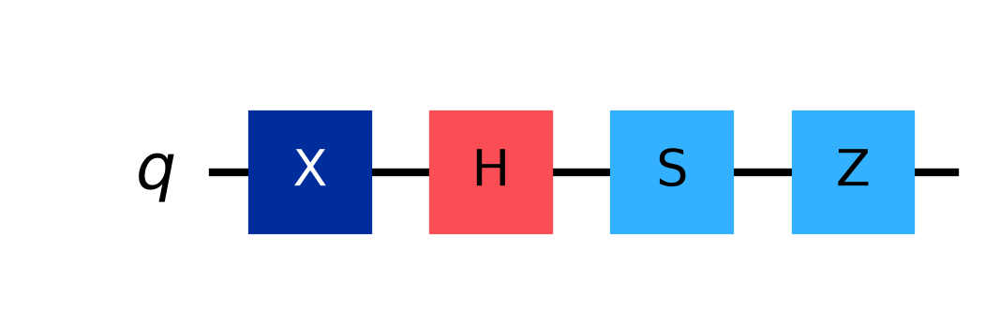

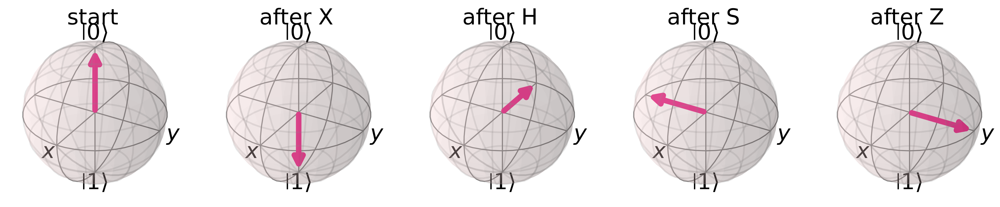

Depth: 4
Gate counts: {'x': 1, 'h': 1, 's': 1, 'z': 1}


In [10]:
q4 = QuantumCircuit(1)
sequence = ["x", "h", "s", "z"]

for i, gate in enumerate(sequence, 1):
    getattr(q4, gate)(0)
    sv = Statevector.from_instruction(q4)
    print(f"After gate {i} ({gate.upper()}):", np.round(sv.data, 3),
          " Bloch:", np.round(bloch_xyz(sv), 3))

show_circuit(q4, "Task 4 - Complete Navigation Circuit")
display(bloch_evolution(q4))

print("Depth:", q4.depth())
print("Gate counts:", dict(q4.count_ops()))

In [11]:
# Extension: search every 4-gate circuit visiting the same states
from itertools import product

allowed = ["x", "y", "z", "h", "s", "t"]
targets = [Statevector.from_label(l) for l in ["1", "-", "l", "r"]]

def visits_all(seq):
    qc = QuantumCircuit(1)
    for gate, target in zip(seq, targets):
        getattr(qc, gate)(0)
        if not Statevector.from_instruction(qc).equiv(target):
            return False
    return True

solutions = [s for s in product(allowed, repeat=4) if visits_all(s)]
print("Circuits visiting |1>, |->, |-i>, |+i> in order:")
for seq in solutions:
    phase = sum(g in ("z", "s", "t") for g in seq)
    print("  ", " -> ".join(g.upper() for g in seq),
          "| phase gates:", phase)

Circuits visiting |1>, |->, |-i>, |+i> in order:
   X -> H -> S -> X | phase gates: 1
   X -> H -> S -> Z | phase gates: 2
   X -> H -> S -> H | phase gates: 1
   Y -> H -> S -> X | phase gates: 1
   Y -> H -> S -> Z | phase gates: 2
   Y -> H -> S -> H | phase gates: 1


### Observation

| Step | Gate | State | Why the transition happens |
| --- | --- | --- | --- |
| 1 | X | $|1\rangle$ | X flips $|0\rangle$ to $|1\rangle$ (rotation by $\pi$ about x) |
| 2 | H | $|-\rangle$ | H maps $|1\rangle$ to $(|0\rangle - |1\rangle)/\sqrt{2}$ |
| 3 | S | $|-i\rangle$ | S multiplies the $|1\rangle$ amplitude by $i$: $-1 \to -i$ |
| 4 | Z | $|+i\rangle$ | Z multiplies the $|1\rangle$ amplitude by $-1$: $-i \to +i$ |
*Navigation sequence X, H, S, Z*

Every intermediate statevector and Bloch vector matched the target, so the circuit **navigates all five states with 4 gates and depth 4**. The exhaustive search found **exactly six valid 4-gate circuits**: the first move can be X or Y, the middle moves must be H then S, and the last move can be X, Z or H. Since each state change needs at least one gate, four gates is the minimum, so **more than one optimal navigation circuit exists**. Among them X H S X and X H S H use only **one phase gate** against two in X H S Z, so they are the better choice when phase gates are counted.

## Task 5: Beyond the Bloch Sphere

### Problem Statement

Investigate whether the Bloch sphere still describes multi-qubit states. For the product state $|+\rangle|1\rangle$, the Bell state $(|00\rangle + |11\rangle)/\sqrt{2}$, the GHZ state $(|000\rangle + |111\rangle)/\sqrt{2}$ and the W state $(|001\rangle + |010\rangle + |100\rangle)/\sqrt{3}$: build the circuit, plot the individual Bloch spheres, plot the histogram, display the statevector and decide whether the Bloch spheres describe the state completely. Finally propose a criterion for when the Bloch sphere is sufficient.

### Program


Task 5 - Product State


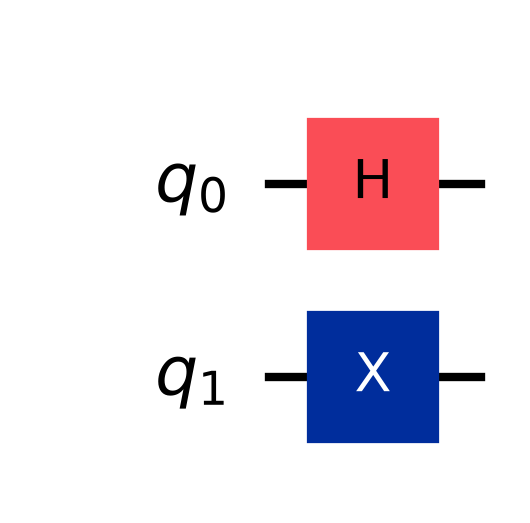

Statevector: [0.   +0.j 0.   +0.j 0.707+0.j 0.707+0.j]


Measurement counts: {'10': 496, '11': 528}


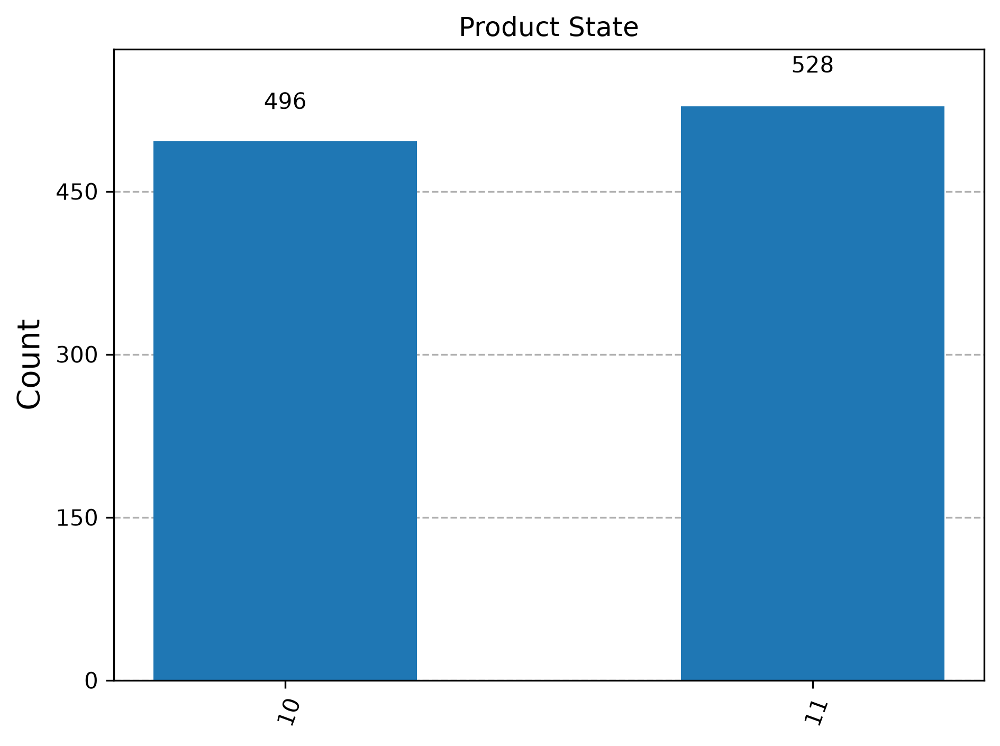

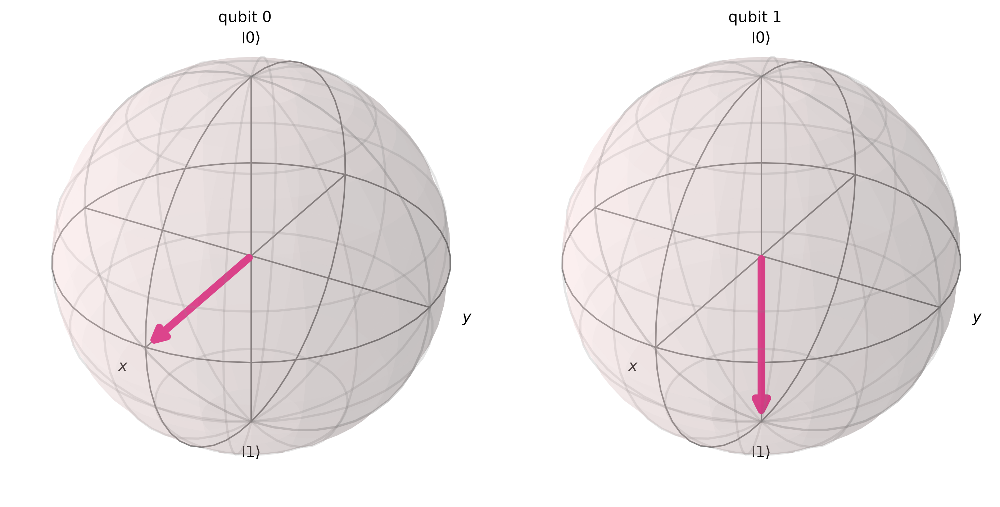


Task 5 - Bell State


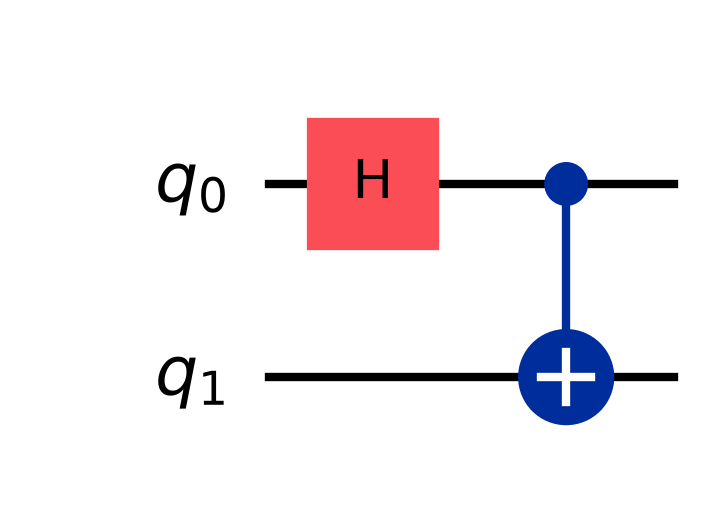

Statevector: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]


Measurement counts: {'00': 504, '11': 520}


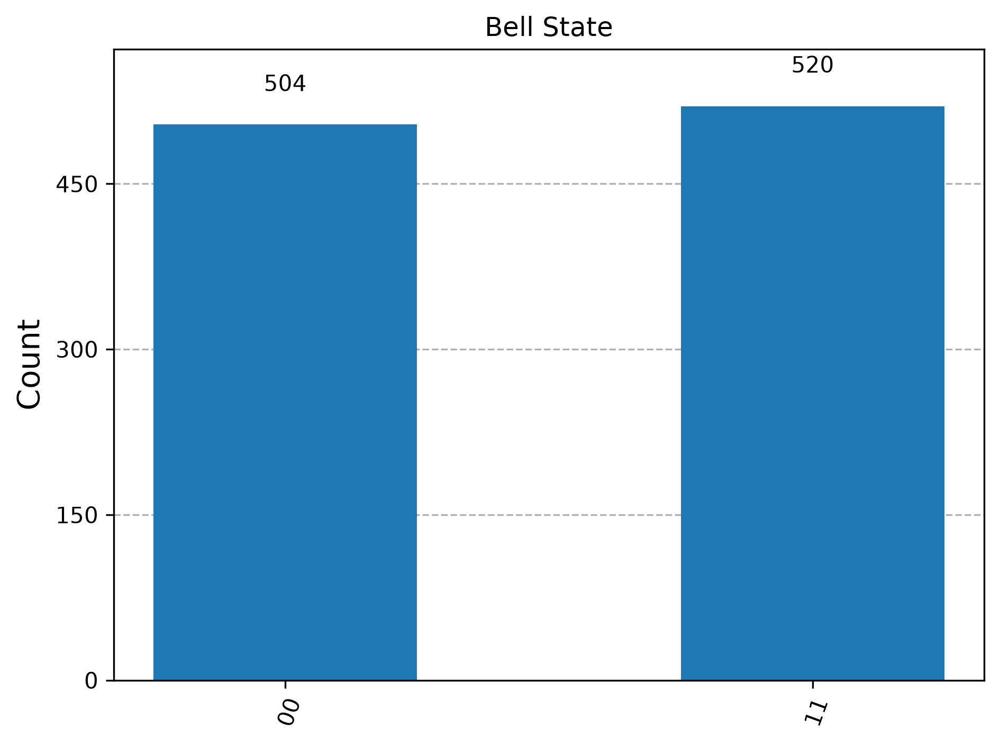

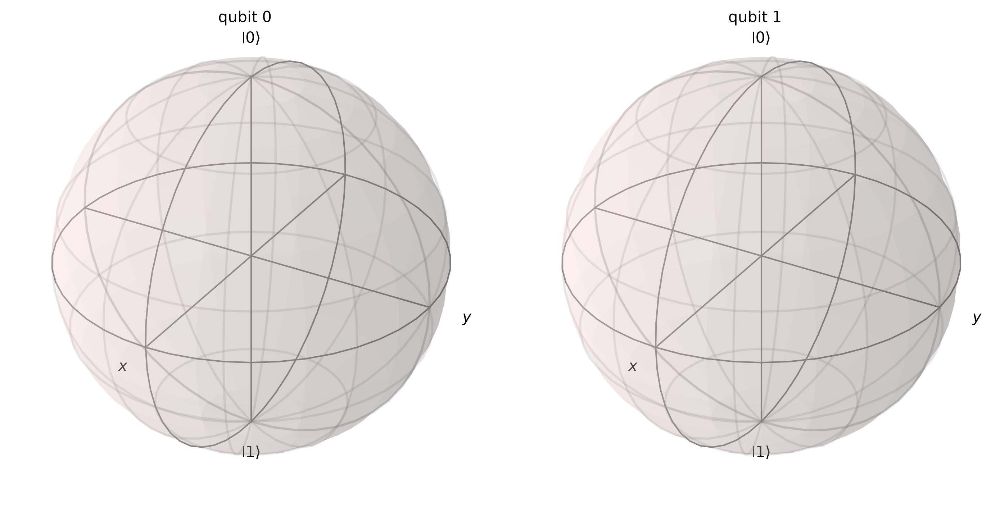


Task 5 - GHZ State


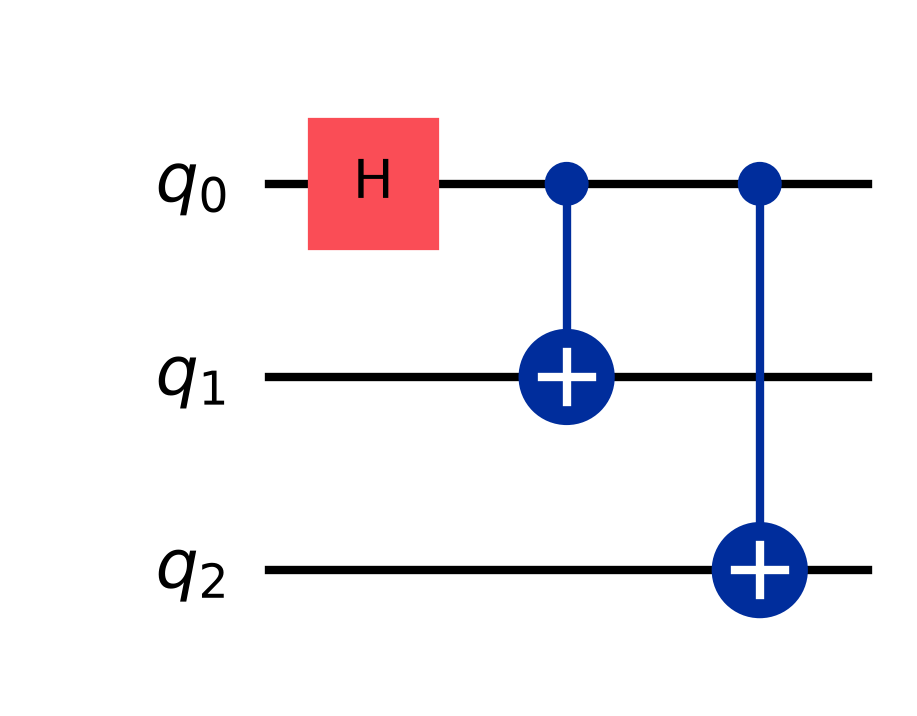

Statevector: [0.707+0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j
 0.707+0.j]


Measurement counts: {'000': 496, '111': 528}


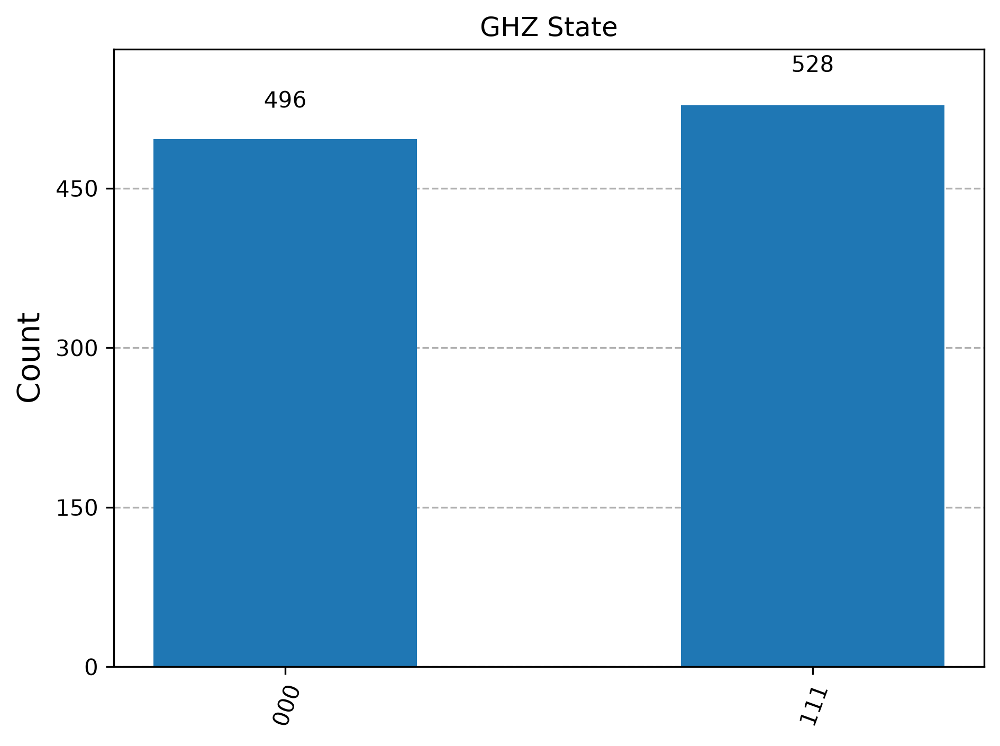

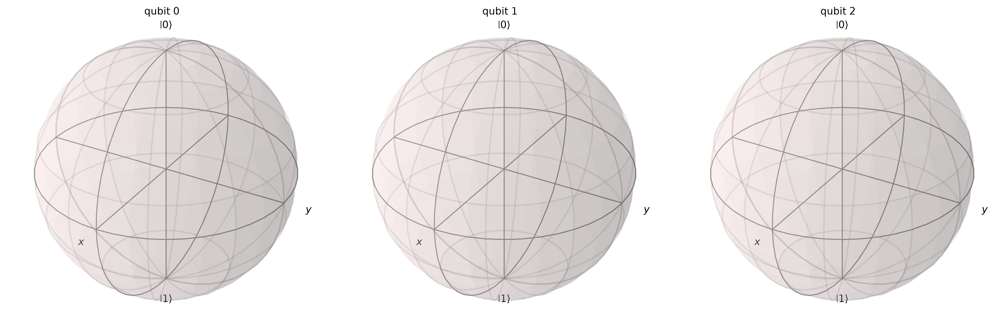


Task 5 - W State


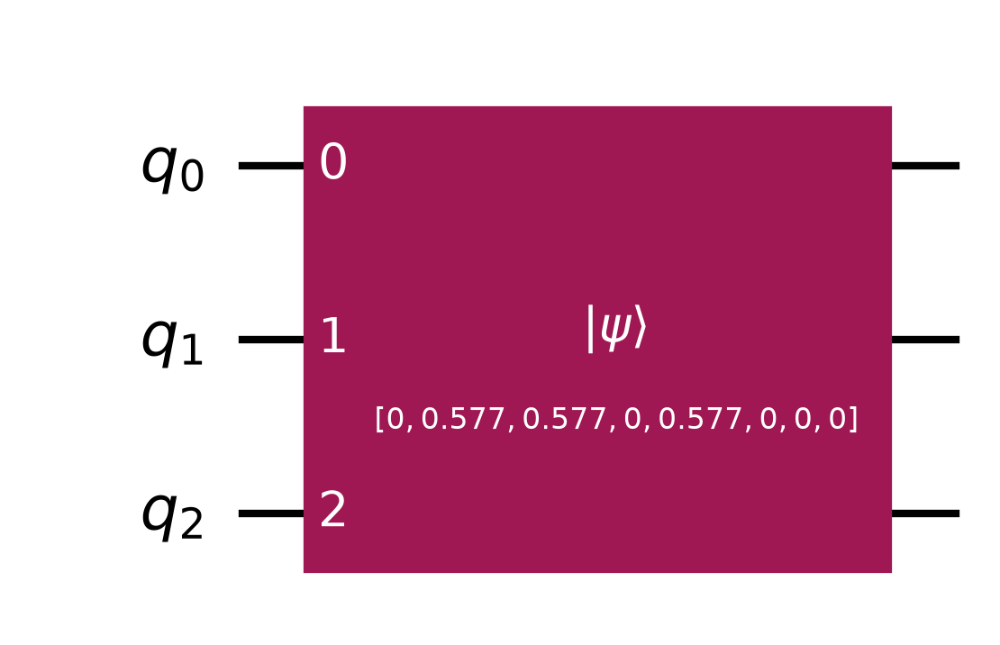

Statevector: [0.   +0.j 0.577+0.j 0.577+0.j 0.   +0.j 0.577+0.j 0.   +0.j 0.   +0.j
 0.   +0.j]


Measurement counts: {'010': 351, '001': 342, '100': 331}


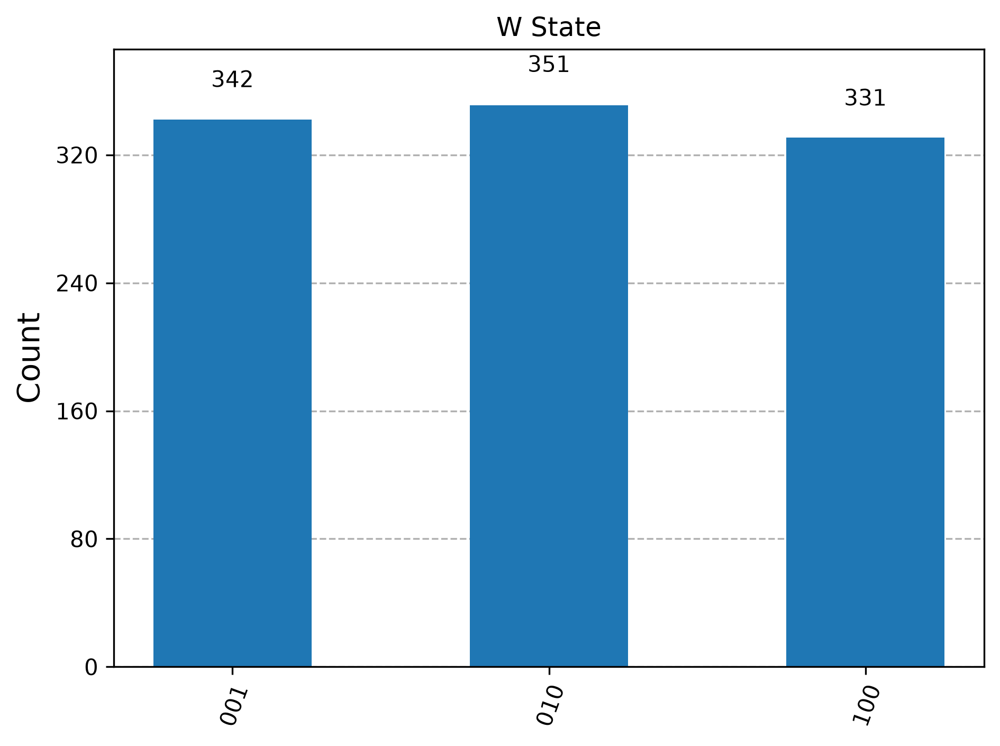

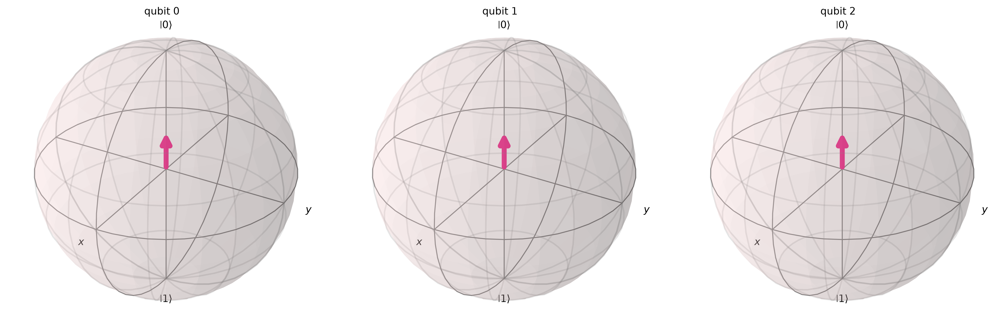

In [12]:
# Product state |+>|1>
product = QuantumCircuit(2)
product.h(0)
product.x(1)

# Bell state (|00> + |11>) / sqrt(2)
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

# GHZ state (|000> + |111>) / sqrt(2)
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(0, 2)

# W state (|001> + |010> + |100>) / sqrt(3)
w = QuantumCircuit(3)
state = np.zeros(8, dtype=complex)
state[1] = 1 / np.sqrt(3)
state[2] = 1 / np.sqrt(3)
state[4] = 1 / np.sqrt(3)
w.initialize(state, [0, 1, 2])

states = [
    ("Product State", product),
    ("Bell State", bell),
    ("GHZ State", ghz),
    ("W State", w),
]

for name, qc in states:
    show_circuit(qc, "Task 5 - " + name)
    show_state(qc)
    show_histogram(qc, name)
    display(plot_bloch_multivector(
        Statevector.from_instruction(qc)
    ))

### Observation

| State | Histogram | Single-qubit Bloch vectors | Bloch sphere sufficient? |
| --- | --- | --- | --- |
| $|+\rangle|1\rangle$ | 10 and 11, about 50/50 | $(1,0,0)$ and $(0,0,-1)$, full length | Yes |
| Bell | 00 and 11, about 50/50 | both at the origin | No |
| GHZ | 000 and 111, about 50/50 | all three at the origin | No |
| W | 001, 010, 100, about 1/3 each | all three $(0,0,1/3)$, shortened | No |
*Entanglement investigation*

For the product state each qubit has a **unit-length Bloch vector** and the two spheres reproduce the full statevector. For the Bell, GHZ and W states the **individual Bloch vectors shrink or vanish**: the reduced state of each qubit is mixed, so the spheres cannot show the correlations seen in the histogram (00 and 11 only, never 01 or 10).

**Criterion**: the Bloch sphere is a complete description only when every single-qubit Bloch vector has length 1, which happens exactly when the state is a product of pure single-qubit states. A vector of length less than 1 signals entanglement, and then the global statevector (or density matrix) is required.

## Conclusion

The same single-qubit state can be reached by many gate sequences, and the transpiler reliably finds the shortest one; a shared output state does not imply a shared unitary. The gates X, Y, Z, H, S and T were classified experimentally by axis, angle, phase and self-inverse behaviour. Finally, the Bloch sphere describes product states completely but fails for entangled states, where the single-qubit vectors shrink toward the origin.